In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.font_manager as fm
import seaborn as sns
from matplotlib import rcParams

fm.fontManager.addfont('/home/marrma/.fonts/NotoSansCJKsc-Regular.otf')
fm._load_fontmanager(try_read_cache=False)

rcParams['font.sans-serif'] = ['Noto Sans CJK SC']
rcParams['axes.unicode_minus'] = False
rcParams['font.size'] = 11
rcParams['axes.titlesize'] = 13
rcParams['axes.labelsize'] = 12
rcParams['xtick.labelsize'] = 10
rcParams['ytick.labelsize'] = 10
rcParams['legend.fontsize'] = 9
rcParams['figure.dpi'] = 150
rcParams['savefig.dpi'] = 300
rcParams['savefig.bbox'] = 'tight'
rcParams['axes.linewidth'] = 1.0

print('Libraries imported successfully. CJK font registered.')

Libraries imported successfully. CJK font registered.


In [36]:

raw = pd.read_excel('results_release.xlsx', header=None)


ALGO_NAMES = ['冒泡排序', '选择排序', '快速排序', '插入排序', '希尔排序', '桶排序']
ALGO_NAMES_EN = ['Bubble', 'Selection', 'Quick', 'Insertion', 'Shell', 'Bucket']


section_defs = [
    (3,   'i', '完全逆序'),
    (15,  'i', '完全顺序'),
    (27,  'i', '均匀分布'),
    (39,  'i', '正态分布'),
    (51,  'd', '完全逆序'),
    (63,  'd', '完全顺序'),
    (75,  'd', '均匀分布'),
    (87,  'd', '正态分布'),
]

records = []
for start_row, dtype, dist in section_defs:
    for offset in range(9):
        data_row = start_row + 2 + offset
        N_val = raw.iloc[data_row, 0]
        if pd.isna(N_val):
            break
        N_val = int(N_val)
        for j, algo in enumerate(ALGO_NAMES):
            time_val = raw.iloc[data_row, 1 + j]
            cmp_val  = raw.iloc[data_row, 7 + j]
            asg_val  = raw.iloc[data_row, 13 + j]
            if time_val == -1 or cmp_val == -1 or asg_val == -1:
                time_val = np.nan
                cmp_val = np.nan
                asg_val = np.nan
            records.append({
                '数据类型': dtype,
                '数据构型': dist,
                '规模N': N_val,
                '算法': algo,
                '算法英文': ALGO_NAMES_EN[j],
                '执行时间_s': float(time_val) if not pd.isna(time_val) else np.nan,
                '比较次数': float(cmp_val) if not pd.isna(cmp_val) else np.nan,
                '赋值次数': float(asg_val) if not pd.isna(asg_val) else np.nan,
            })

df = pd.DataFrame(records)
print(f'Total records: {len(df)}')
print(f'Columns: {df.columns.tolist()}')
print(f'\nData types: {df["数据类型"].unique()}')
print(f'Distributions: {df["数据构型"].unique()}')
print(f'Algorithms: {df["算法"].unique()}')
print(f'N values: {sorted(df["规模N"].unique())}')
df.head(12)

Total records: 432
Columns: ['数据类型', '数据构型', '规模N', '算法', '算法英文', '执行时间_s', '比较次数', '赋值次数']

Data types: ['i' 'd']
Distributions: ['完全逆序' '完全顺序' '均匀分布' '正态分布']
Algorithms: ['冒泡排序' '选择排序' '快速排序' '插入排序' '希尔排序' '桶排序']
N values: [np.int64(1024), np.int64(2048), np.int64(4096), np.int64(8192), np.int64(16384), np.int64(32768), np.int64(65536), np.int64(131072), np.int64(262144)]


,数据类型,数据构型,规模N,算法,算法英文,执行时间_s,比较次数,赋值次数
0,i,完全逆序,1024,冒泡排序,Bubble,0.002522,523776.0,1571328.0
1,i,完全逆序,1024,选择排序,Selection,0.000897,523776.0,1536.0
2,i,完全逆序,1024,快速排序,Quick,0.000024,9238.0,3585.0
3,i,完全逆序,1024,插入排序,Insertion,0.001290,523776.0,525822.0
4,i,完全逆序,1024,希尔排序,Shell,0.000049,13314.0,23554.0
5,i,完全逆序,1024,桶排序,Bucket,0.000096,3069.0,1024.0
6,i,完全逆序,2048,冒泡排序,Bubble,0.010063,2096128.0,6288384.0
7,i,完全逆序,2048,选择排序,Selection,0.003105,2096128.0,3072.0
8,i,完全逆序,2048,快速排序,Quick,0.000037,20504.0,7169.0
9,i,完全逆序,2048,插入排序,Insertion,0.005235,2096128.0,2100222.0


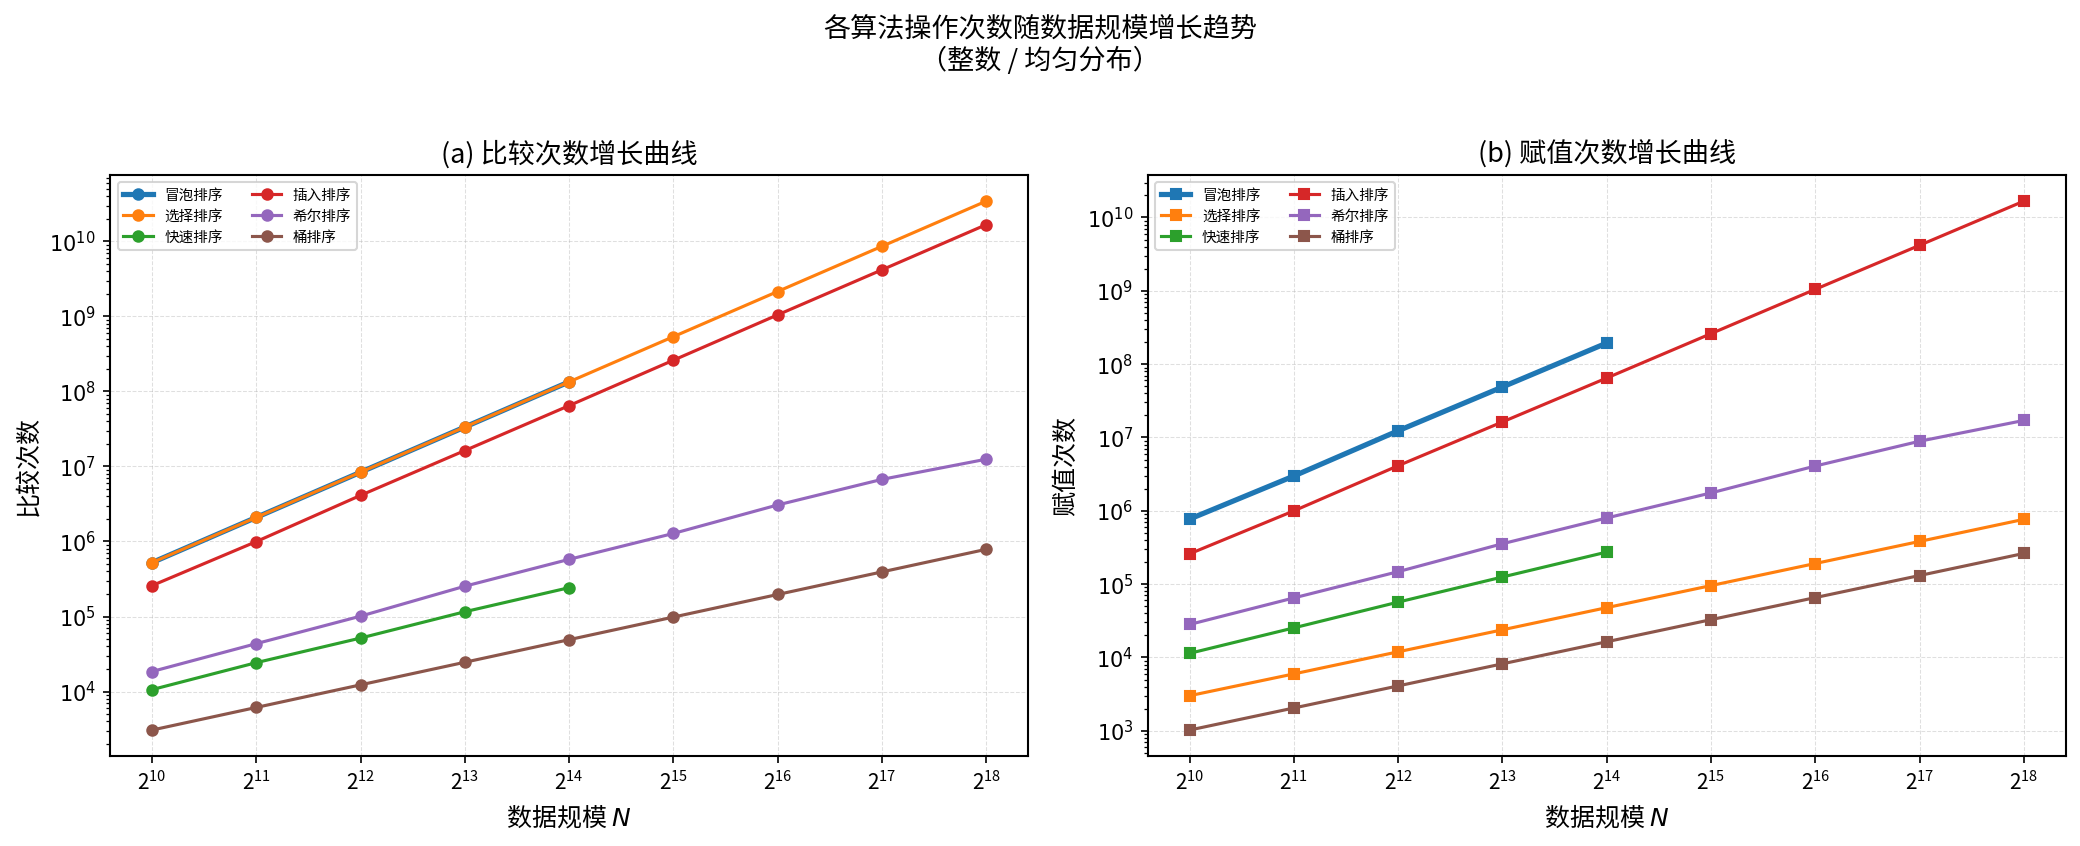

In [30]:
# ========== 图表 2: 操作次数增长图（Y轴 Log10） ==========
# 固定条件：整数类型，均匀分布
mask_2 = (df['数据类型'] == 'i') & (df['数据构型'] == '均匀分布')
df_2 = df[mask_2].dropna(subset=['比较次数', '赋值次数']).copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 图2-a: 比较次数
ax = axes[0]
for algo in ALGO_NAMES:
    sub = df_2[df_2['算法'] == algo].sort_values('规模N')
    lw = 2.5 if algo == '冒泡排序' else 1.5  # 冒泡加粗以区别于选择排序（二者完全重叠）
    ax.plot(sub['规模N'], sub['比较次数'], marker='o', linewidth=lw, markersize=5, label=algo)
ax.set_xlabel('数据规模 $N$')
ax.set_ylabel('比较次数')
ax.set_title('(a) 比较次数增长曲线')
ax.set_yscale('log', base=10)
ax.set_xscale('log', base=2)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'$10^{{{int(np.log10(x))}}}$'))
ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=10))
ax.legend(fontsize=7, ncol=2)
ax.grid(True, linestyle='--', alpha=0.4, linewidth=0.5)

# 图2-b: 赋值次数
ax = axes[1]
for algo in ALGO_NAMES:
    sub = df_2[df_2['算法'] == algo].sort_values('规模N')
    lw = 2.5 if algo == '冒泡排序' else 1.5
    ax.plot(sub['规模N'], sub['赋值次数'], marker='s', linewidth=lw, markersize=5, label=algo)
ax.set_xlabel('数据规模 $N$')
ax.set_ylabel('赋值次数')
ax.set_title('(b) 赋值次数增长曲线')
ax.set_yscale('log', base=10)
ax.set_xscale('log', base=2)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'$10^{{{int(np.log10(x))}}}$'))
ax.yaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=10))
ax.legend(fontsize=7, ncol=2)
ax.grid(True, linestyle='--', alpha=0.4, linewidth=0.5)

fig.suptitle('各算法操作次数随数据规模增长趋势\n（整数 / 均匀分布）',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('fig2_operations_log_scale.png', dpi=300)
plt.show()

/tmp/ipykernel_1958/1111841053.py:38: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_ylim(0, 1e9)


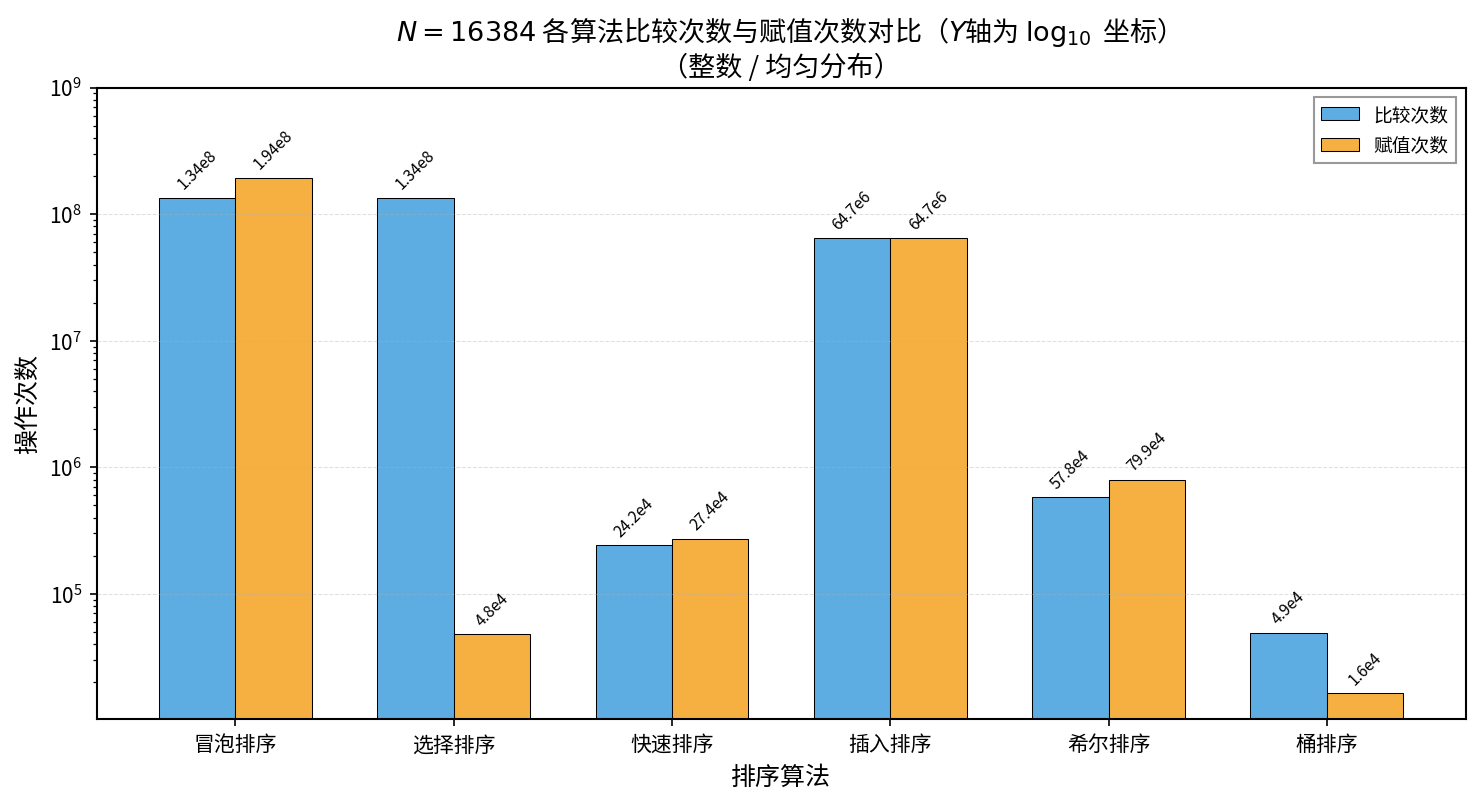

In [37]:
# ========== 图表 3: N=16384 分组柱状图 ==========
mask_3 = (df['数据类型'] == 'i') & (df['数据构型'] == '均匀分布') & (df['规模N'] == 16384)
df_3 = df[mask_3].dropna(subset=['比较次数', '赋值次数']).copy()

fig, ax = plt.subplots(figsize=(10, 5.5))

x = np.arange(len(ALGO_NAMES))
width = 0.35

cmp_vals = [df_3[df_3['算法'] == a]['比较次数'].values[0] for a in ALGO_NAMES]
asg_vals = [df_3[df_3['算法'] == a]['赋值次数'].values[0] for a in ALGO_NAMES]

bars1 = ax.bar(x - width/2, cmp_vals, width, label='比较次数',
               color='#5DADE2', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, asg_vals, width, label='赋值次数',
               color='#F5B041', edgecolor='black', linewidth=0.5)

# Y 轴取对数，缩小数量级差异
ax.set_yscale('log', base=10)

# 在柱子上方标注数值
def format_val(v):
    if v >= 1e8:
        return f'{v/1e8:.2f}e8'
    elif v >= 1e6:
        return f'{v/1e6:.1f}e6'
    elif v >= 1e4:
        return f'{v/1e4:.1f}e4'
    else:
        return f'{v:.0f}'

for bar, val in zip(bars1, cmp_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.1,
            format_val(val), ha='center', va='bottom', fontsize=7.5, rotation=45)
for bar, val in zip(bars2, asg_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.1,
            format_val(val), ha='center', va='bottom', fontsize=7.5, rotation=45)
ax.set_ylim(0, 1e9)

ax.set_xlabel('排序算法')
ax.set_ylabel('操作次数')
ax.set_title('$N=16384$ 各算法比较次数与赋值次数对比（$Y$轴为 $\\log_{10}$ 坐标）\n（整数 / 均匀分布）')
ax.set_xticks(x)
ax.set_xticklabels(ALGO_NAMES)
ax.legend(frameon=True, fancybox=False, edgecolor='gray')
ax.grid(True, axis='y', linestyle='--', alpha=0.4, linewidth=0.5)

plt.tight_layout()
plt.savefig('fig3_grouped_bar_n16384.png', dpi=300)
plt.show()

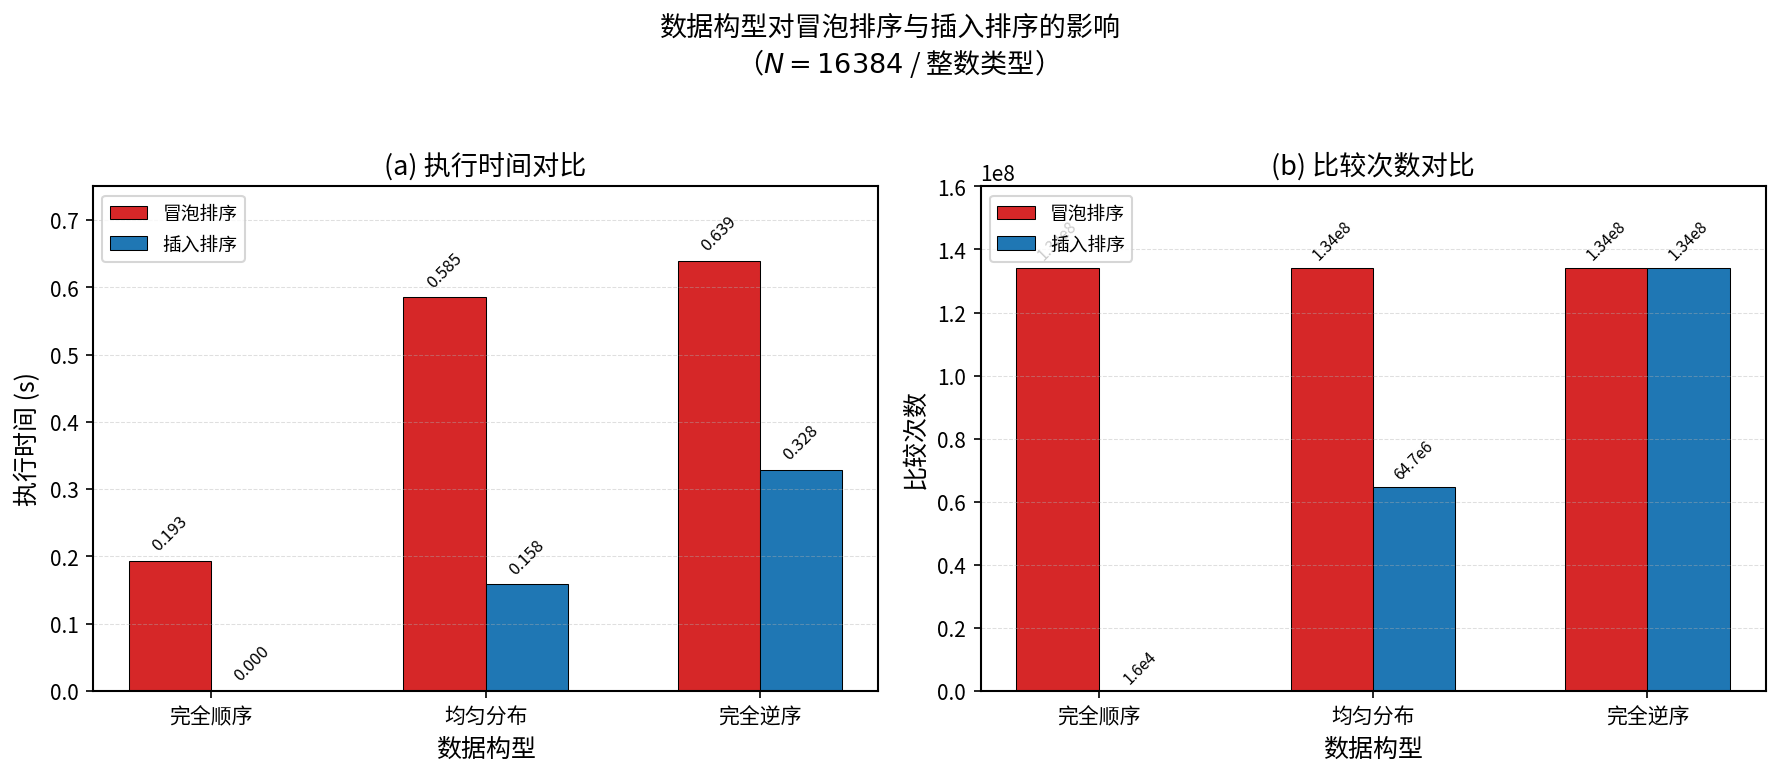

In [10]:
# ========== 图表 4: 特殊构型对比（冒泡 vs 插入） ==========
mask_4 = (df['数据类型'] == 'i') & (df['规模N'] == 16384) & \
         (df['数据构型'].isin(['完全顺序', '完全逆序', '均匀分布'])) & \
         (df['算法'].isin(['冒泡排序', '插入排序']))
df_4 = df[mask_4].dropna(subset=['执行时间_s']).copy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

configs = ['完全顺序', '均匀分布', '完全逆序']
colors_4 = {'冒泡排序': '#d62728', '插入排序': '#1f77b4'}

ax = axes[0]
x = np.arange(len(configs))
width = 0.3
for i, algo in enumerate(['冒泡排序', '插入排序']):
    vals = []
    for cfg in configs:
        row = df_4[(df_4['算法'] == algo) & (df_4['数据构型'] == cfg)]
        vals.append(row['执行时间_s'].values[0] if len(row) else 0)
    bars = ax.bar(x + (i - 0.5) * width, vals, width, label=algo,
                  color=colors_4[algo], edgecolor='black', linewidth=0.5)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8, rotation=45)
ax.set_xlabel('数据构型')
ax.set_ylabel('执行时间 (s)')
ax.set_title('(a) 执行时间对比')
ax.set_ylim(0, 0.75)
ax.set_xticks(x)
ax.set_xticklabels(configs)
ax.legend()
ax.grid(True, axis='y', linestyle='--', alpha=0.4, linewidth=0.5)

ax = axes[1]
for i, algo in enumerate(['冒泡排序', '插入排序']):
    vals = []
    for cfg in configs:
        row = df_4[(df_4['算法'] == algo) & (df_4['数据构型'] == cfg)]
        vals.append(row['比较次数'].values[0] if len(row) else 0)
    bars = ax.bar(x + (i - 0.5) * width, vals, width, label=algo,
                  color=colors_4[algo], edgecolor='black', linewidth=0.5)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals)*0.01,
                format_val(val), ha='center', va='bottom', fontsize=7.5, rotation=45)

ax.set_ylim(0, 1.6e8)
ax.set_xlabel('数据构型')
ax.set_ylabel('比较次数')
ax.set_title('(b) 比较次数对比')
ax.set_xticks(x)
ax.set_xticklabels(configs)
ax.legend()
ax.grid(True, axis='y', linestyle='--', alpha=0.4, linewidth=0.5)

fig.suptitle('数据构型对冒泡排序与插入排序的影响\n（$N=16384$ / 整数类型）', fontsize=13, y=1.03)
plt.tight_layout()
plt.savefig('fig4_config_impact.png', dpi=300)
plt.show()

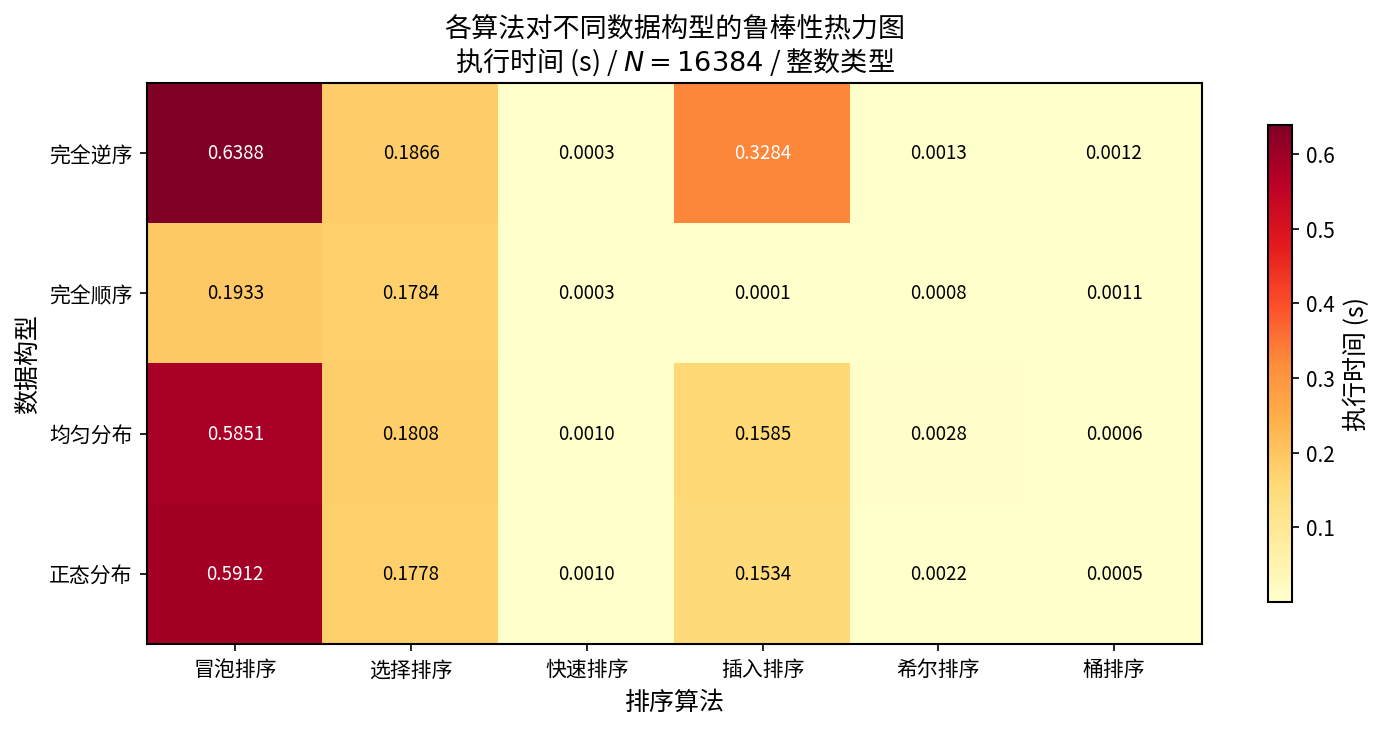

In [11]:
# ========== 图表 5: 热力图 —— 各算法 × 各数据构型的执行时间 ==========
mask_5 = (df['数据类型'] == 'i') & (df['规模N'] == 16384)
df_5 = df[mask_5].dropna(subset=['执行时间_s']).copy()

configs_order = ['完全逆序', '完全顺序', '均匀分布', '正态分布']
algos_order = ALGO_NAMES

heatmap_data = np.zeros((len(configs_order), len(algos_order)))
annot_data = np.empty((len(configs_order), len(algos_order)), dtype=object)

for i, cfg in enumerate(configs_order):
    for j, algo in enumerate(algos_order):
        row = df_5[(df_5['数据构型'] == cfg) & (df_5['算法'] == algo)]
        if len(row):
            t = row['执行时间_s'].values[0]
            heatmap_data[i, j] = t
            annot_data[i, j] = f'{t:.4f}'
        else:
            heatmap_data[i, j] = np.nan
            annot_data[i, j] = 'N/A'

fig, ax = plt.subplots(figsize=(10, 5))

vmin = np.nanmin(heatmap_data)
vmax = np.nanmax(heatmap_data)

im = ax.imshow(heatmap_data, cmap='YlOrRd', aspect='auto', vmin=vmin, vmax=vmax)


for i in range(len(configs_order)):
    for j in range(len(algos_order)):
        val = heatmap_data[i, j]
        if not np.isnan(val):

            norm_val = (val - vmin) / (vmax - vmin) if vmax > vmin else 0
            text_color = 'white' if norm_val > 0.5 else 'black'
            ax.text(j, i, f'{val:.4f}', ha='center', va='center',
                    fontsize=9, fontweight='bold', color=text_color)

ax.set_xticks(range(len(algos_order)))
ax.set_xticklabels(algos_order)
ax.set_yticks(range(len(configs_order)))
ax.set_yticklabels(configs_order)
ax.set_xlabel('排序算法')
ax.set_ylabel('数据构型')
ax.set_title('各算法对不同数据构型的鲁棒性热力图\n执行时间 (s) / $N=16384$ / 整数类型')

cbar = plt.colorbar(im, ax=ax, shrink=0.85)
cbar.set_label('执行时间 (s)')

plt.tight_layout()
plt.savefig('fig5_heatmap_robustness.png', dpi=300)
plt.show()

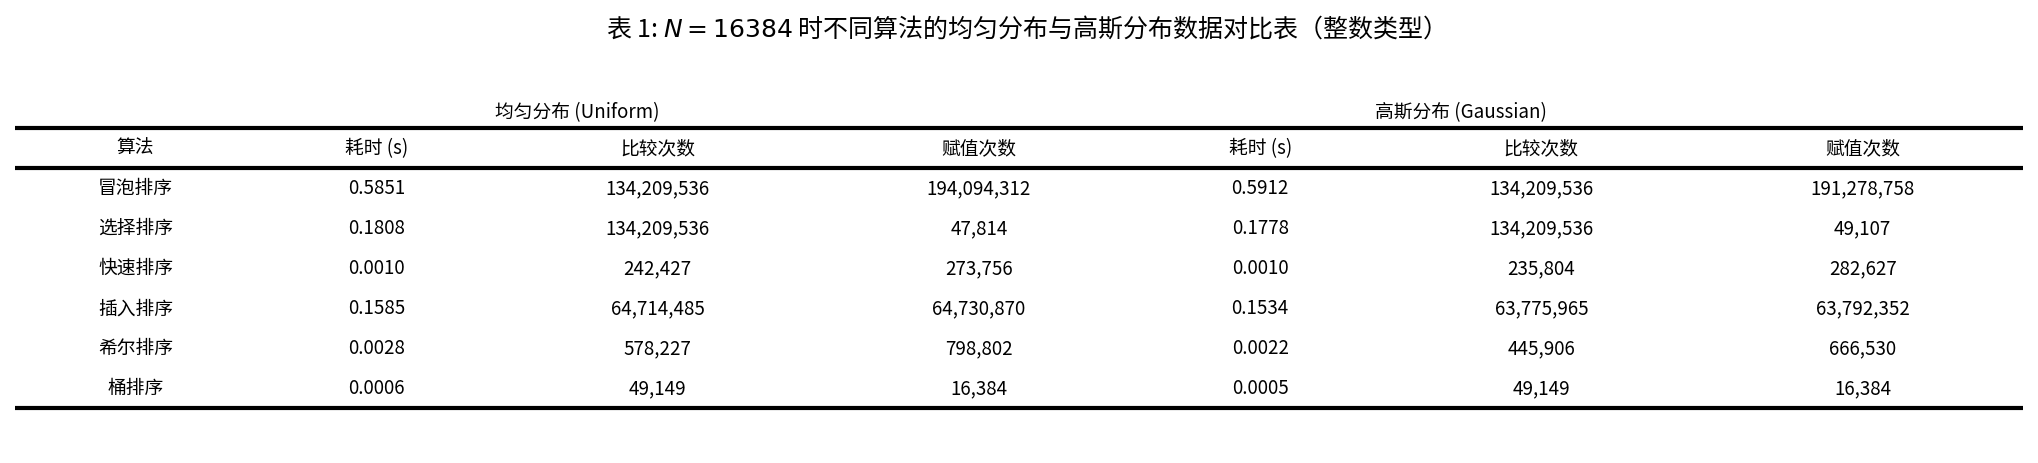

In [38]:
# ========== 表格 1: N=16384 学术三线表 ==========
mask_t1 = (df['数据类型'] == 'i') & (df['规模N'] == 16384) & \
          (df['数据构型'].isin(['均匀分布', '正态分布']))
df_t1 = df[mask_t1].dropna(subset=['执行时间_s']).copy()


table_data = []
for algo in ALGO_NAMES:
    row_uniform = df_t1[(df_t1['算法'] == algo) & (df_t1['数据构型'] == '均匀分布')]
    row_normal  = df_t1[(df_t1['算法'] == algo) & (df_t1['数据构型'] == '正态分布')]

    table_data.append({
        '算法': algo,
        '均匀分布-耗时(s)': f"{row_uniform['执行时间_s'].values[0]:.4f}" if len(row_uniform) else '-',
        '均匀分布-比较次数': f"{row_uniform['比较次数'].values[0]:,.0f}" if len(row_uniform) else '-',
        '均匀分布-赋值次数': f"{row_uniform['赋值次数'].values[0]:,.0f}" if len(row_uniform) else '-',
        '正态分布-耗时(s)': f"{row_normal['执行时间_s'].values[0]:.4f}" if len(row_normal) else '-',
        '正态分布-比较次数': f"{row_normal['比较次数'].values[0]:,.0f}" if len(row_normal) else '-',
        '正态分布-赋值次数': f"{row_normal['赋值次数'].values[0]:,.0f}" if len(row_normal) else '-',
    })

df_table1 = pd.DataFrame(table_data)

col_labels = ['算法', '耗时 (s)', '比较次数', '赋值次数', '耗时 (s)', '比较次数', '赋值次数']
cell_text = []
for _, row in df_table1.iterrows():
    cell_text.append([row['算法'],
                      row['均匀分布-耗时(s)'], row['均匀分布-比较次数'], row['均匀分布-赋值次数'],
                      row['正态分布-耗时(s)'], row['正态分布-比较次数'], row['正态分布-赋值次数']])

nrows = len(cell_text)
ncols = len(col_labels)

fig, ax = plt.subplots(figsize=(14, 3.5))
ax.axis('off')

# 创建表格，默认无边框
col_widths = [0.12, 0.12, 0.16, 0.16, 0.12, 0.16, 0.16]
table = ax.table(
    cellText=cell_text,
    colLabels=col_labels,
    cellLoc='center',
    loc='center',
    colWidths=col_widths,
    edges='open',
)

table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.0, 1.8)


for (row, col), cell in table.get_celld().items():
    cell.set_facecolor('white')
    cell.set_edgecolor('black')

    if row == 0:
        cell.visible_edges = 'TB'
        cell.set_linewidth(2.0)
        cell.set_text_props(weight='bold', fontsize=9)
    elif row == nrows:
        cell.visible_edges = 'B'
        cell.set_linewidth(2.0)
    else:
        cell.visible_edges = ''
        cell.set_linewidth(0)

# 标题和分组标注
ax.set_title('表 1: $N=16384$ 时不同算法的均匀分布与高斯分布数据对比表（整数类型）',
             fontsize=12, fontweight='bold', pad=25, loc='center')
ax.text(0.28, 0.92, '均匀分布 (Uniform)', transform=ax.transAxes,
        fontsize=9, ha='center', fontstyle='italic')
ax.text(0.72, 0.92, '高斯分布 (Gaussian)', transform=ax.transAxes,
        fontsize=9, ha='center', fontstyle='italic')

plt.tight_layout(pad=2.0)
plt.savefig('table1_academic_three_line.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')
plt.show()

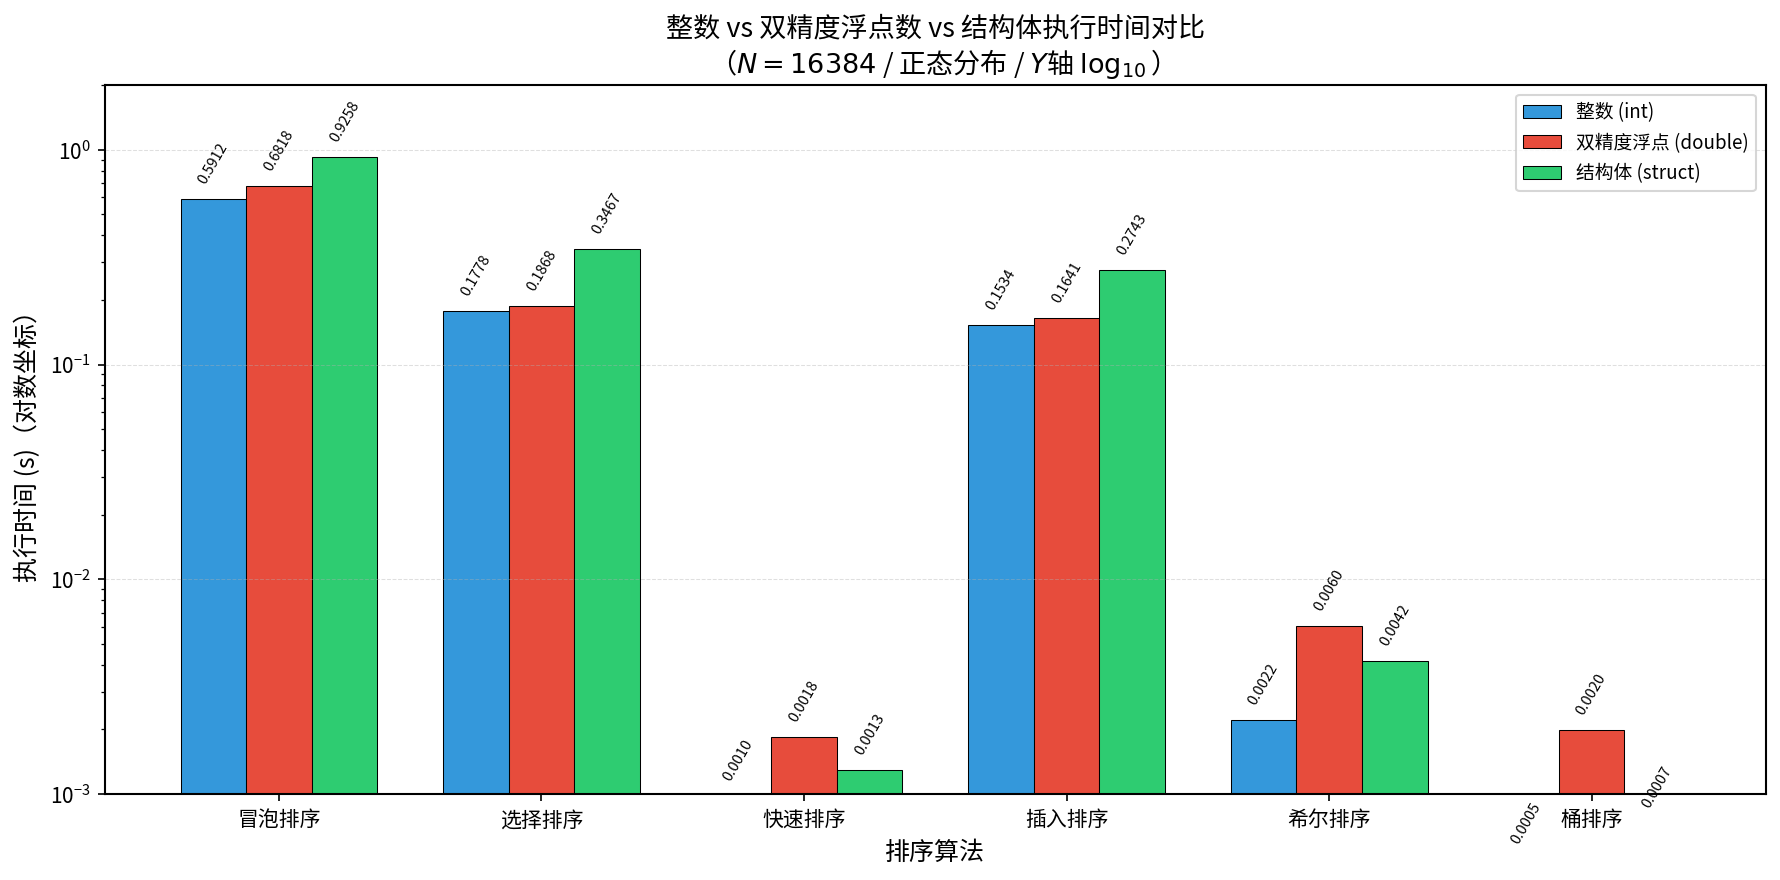

In [39]:
# ========== 图表 7: 整数 vs 双精度浮点 vs 结构体 时间对比（正态分布 N=16384） ==========
mask_extra = (df['数据构型'] == '正态分布') & (df['规模N'] == 16384)
df_extra = df[mask_extra].dropna(subset=['执行时间_s']).copy()


struct_times_16384 = []
for r in range(124, 130):
    time_val = raw.iloc[r, 4]
    struct_times_16384.append(float(time_val))

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(ALGO_NAMES))
width = 0.25

colors = ['#3498DB', '#E74C3C', '#2ECC71']
type_labels = ['整数 (int)', '双精度浮点 (double)', '结构体 (struct)']

for i, (dtype_key, color, label) in enumerate(zip(['i', 'd'], colors[:2], type_labels[:2])):
    vals = []
    for algo in ALGO_NAMES:
        row = df_extra[(df_extra['数据类型'] == dtype_key) & (df_extra['算法'] == algo)]
        vals.append(row['执行时间_s'].values[0] if len(row) else 0)
    bars = ax.bar(x + (i - 1) * width, vals, width, label=label,
                  color=color, edgecolor='black', linewidth=0.5)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.15,
                f'{val:.4f}', ha='center', va='bottom', fontsize=7, rotation=60)


bars = ax.bar(x + 1 * width, struct_times_16384, width,
              label=type_labels[2], color=colors[2], edgecolor='black', linewidth=0.5)
for bar, val in zip(bars, struct_times_16384):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.15,
            f'{val:.4f}', ha='center', va='bottom', fontsize=7, rotation=60)

ax.set_yscale('log', base=10)
ax.set_ylim(1e-3, 2)
ax.set_xlabel('排序算法')
ax.set_ylabel('执行时间 (s)（对数坐标）')
ax.set_title('整数 vs 双精度浮点数 vs 结构体执行时间对比\n（$N=16384$ / 正态分布 / $Y$轴 $\\log_{10}$）')
ax.set_xticks(x)
ax.set_xticklabels(ALGO_NAMES)
ax.legend(loc='upper right')
ax.grid(True, axis='y', linestyle='--', alpha=0.4, linewidth=0.5)

plt.tight_layout()
plt.savefig('fig_int_vs_double_vs_struct_normal.png', dpi=300)
plt.show()


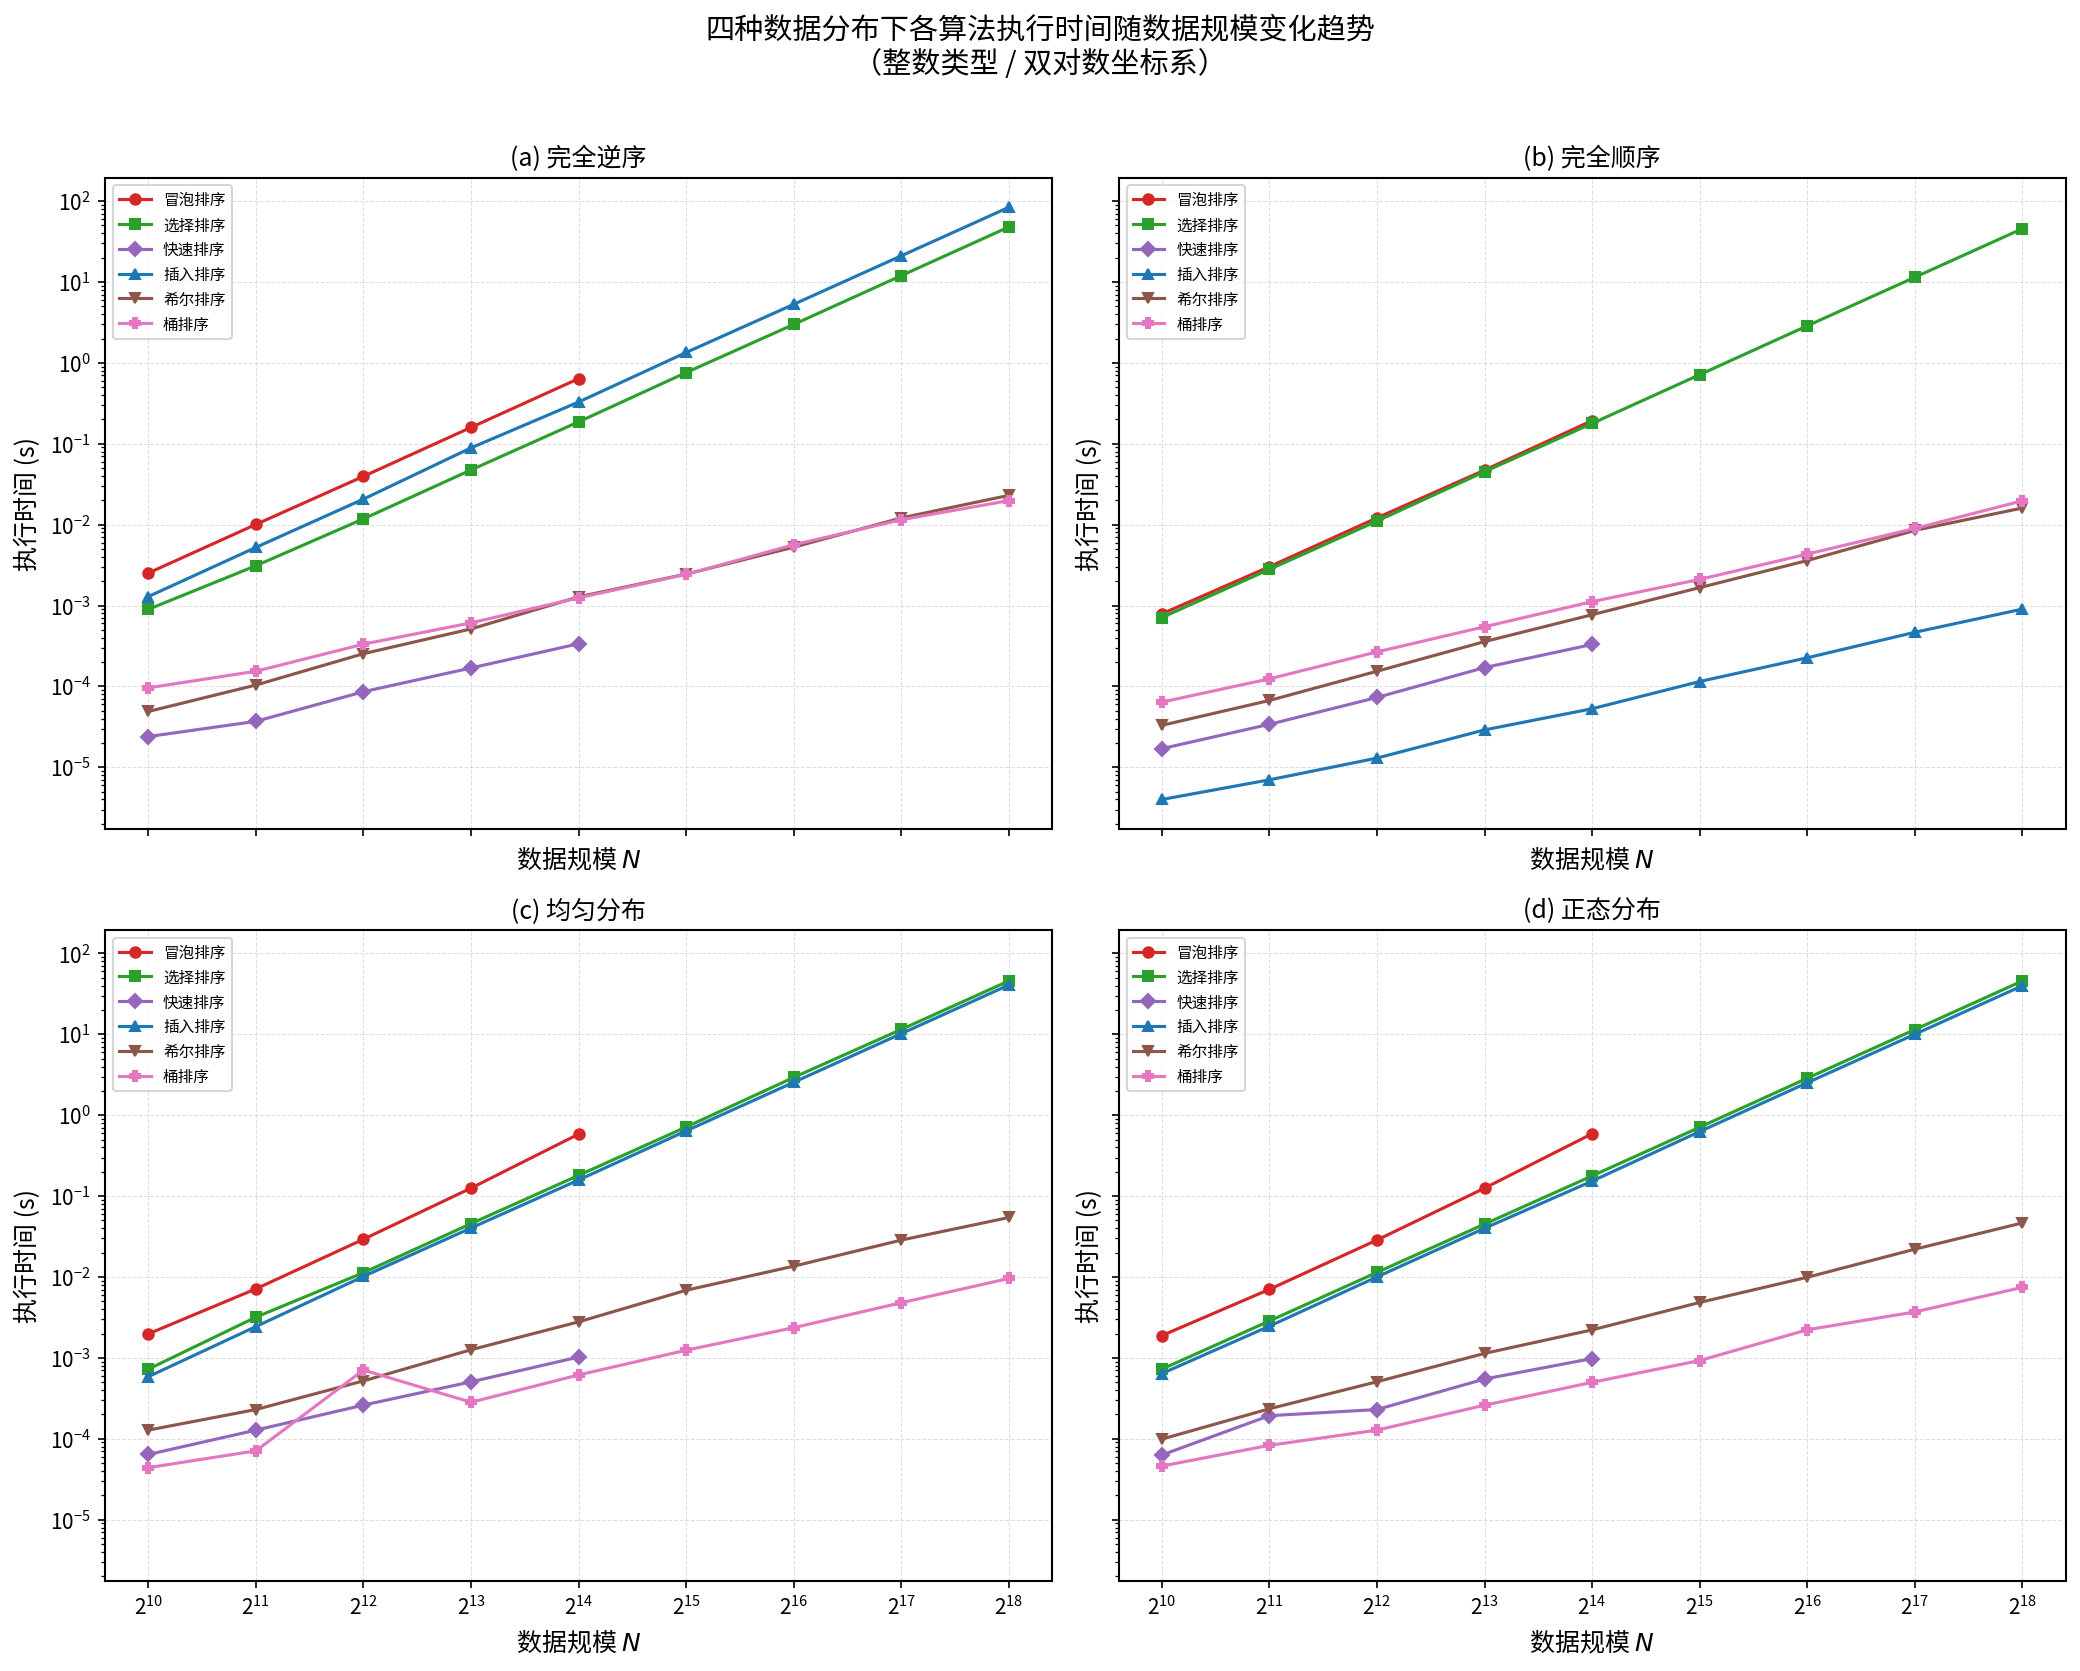

In [26]:
# ========== 图表 6: 四种数据分布下六种算法执行时间对比（双对数坐标） ==========
# 整数类型数据，四个子图分别对应四种数据构型
mask_6 = (df['数据类型'] == 'i')
df_6 = df[mask_6].dropna(subset=['执行时间_s']).copy()

distributions = ['完全逆序', '完全顺序', '均匀分布', '正态分布']
dist_titles = ['(a) 完全逆序', '(b) 完全顺序', '(c) 均匀分布', '(d) 正态分布']

# 六种算法的统一颜色与标记方案
algo_colors = {
    '冒泡排序': '#d62728',
    '选择排序': '#2ca02c',
    '插入排序': '#1f77b4',
    '快速排序': '#9467bd',
    '希尔排序': '#8c564b',
    '桶排序': '#e377c2',
}

algo_markers = {
    '冒泡排序': 'o',
    '选择排序': 's',
    '插入排序': '^',
    '快速排序': 'D',
    '希尔排序': 'v',
    '桶排序': 'P',
}

fig, axes = plt.subplots(2, 2, figsize=(14, 11), sharex=True, sharey=True)

for idx, (dist, ax) in enumerate(zip(distributions, axes.flat)):
    for algo in ALGO_NAMES:
        sub = df_6[(df_6['数据构型'] == dist) & (df_6['算法'] == algo)].sort_values('规模N')
        ax.plot(sub['规模N'], sub['执行时间_s'],
                color=algo_colors[algo], marker=algo_markers[algo],
                linewidth=1.5, markersize=5, label=algo, zorder=3)

    ax.set_title(dist_titles[idx], fontsize=12)
    ax.set_xlabel('数据规模 $N$')
    ax.set_ylabel('执行时间 (s)')
    ax.set_xscale('log', base=2)
    ax.set_yscale('log', base=10)
    ax.grid(True, linestyle='--', alpha=0.4, linewidth=0.5)
    ax.legend(fontsize=7.5, loc='upper left')

fig.suptitle('四种数据分布下各算法执行时间随数据规模变化趋势\n（整数类型 / 双对数坐标系）',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig('fig6_all_algo_all_dist_loglog.png', dpi=300)
plt.show()

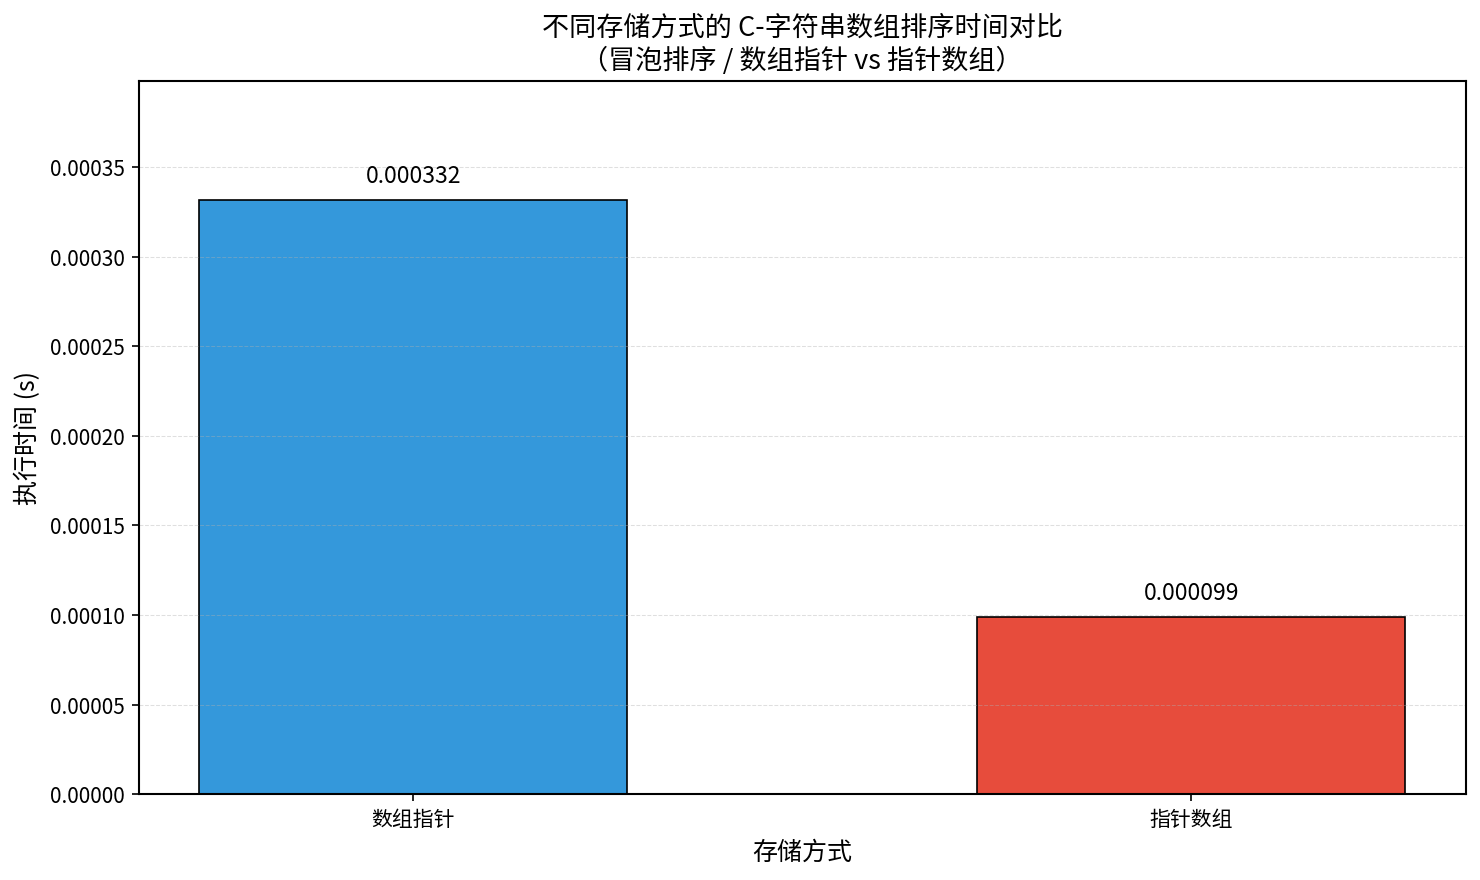

In [41]:
# ========== 图表 9: 数组指针与指针数组的排序时间差异图 ==========
str_types = ['StrA', 'StrB']
str_labels = ['数组指针', '指针数组']

str_times = []
str_cmps = []
str_asns = []
for r in range(145, 147):
    str_times.append(float(raw.iloc[r, 1]))
    str_cmps.append(int(raw.iloc[r, 2]))
    str_asns.append(int(raw.iloc[r, 3]))

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(str_types))
width = 0.55

bar_colors = ['#3498DB', '#E74C3C']

bars = ax.bar(x, str_times, width, color=bar_colors, edgecolor='black', linewidth=0.8)


for bar, val in zip(bars, str_times):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(str_times)*0.02,
            f'{val:.6f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_xlabel('存储方式')
ax.set_ylabel('执行时间 (s)')
ax.set_title('不同存储方式的 C-字符串数组排序时间对比\n（冒泡排序 / 数组指针 vs 指针数组）')
ax.set_xticks(x)
ax.set_xticklabels(str_labels, fontsize=10)

ax.grid(True, axis='y', linestyle='--', alpha=0.4, linewidth=0.5)
ax.set_ylim(0, max(str_times) * 1.2)

plt.tight_layout()
plt.savefig('fig9_string_storage_comparison.png', dpi=300)
plt.show()
